# 01 · Explore the PPD dataset
Run the notebooks in numerical order from the project. Here we audit the supplied CSV, check the score distributions, and identify data quality issues before modeling.

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
from IPython.display import display
from src.preprocessing import FEATURES, GRAPHS, LABELS, TARGET, clean_features, read_data

GRAPHS.mkdir(parents=True, exist_ok=True)
data = read_data()
print(f"Rows: {len(data)} | Columns: {data.shape[1]}")
display(data.dtypes.rename("dtype").to_frame().T)
print("Repeated serial numbers:", data["sr"].duplicated().sum())
print("Identical rows after dropping the serial number:",
      data.drop(columns="sr").duplicated().sum())
print("Duplicate profiles on the selected predictors:",
      clean_features(data).duplicated().sum())

Rows: 800 | Columns: 51


,sr,Age,Residence,Education Level,Marital status,Occupation before latest pregnancy,Monthly income before latest pregnancy,Occupation After Your Latest Childbirth,Current monthly income,Husband's education level,...,Relax/sleep when newborn is tended,Relax/sleep when the newborn is asleep,Angry after latest child birth,Feeling for regular activities,Depression before pregnancy,Depression during pregnancy,PHQ9 Score,PHQ9 Result,EPDS Score,EPDS Result
dtype,int64,int64,object,object,object,object,object,object,object,object,...,object,object,object,object,object,object,int64,object,int64,object


Repeated serial numbers: 0
Identical rows after dropping the serial number: 0
Duplicate profiles on the selected predictors: 3


In [2]:
missing = data.isna().sum()
display(missing[missing > 0].rename("blank_count").to_frame())
display(data[TARGET].value_counts().rename("raw_target_count").to_frame())
labels = data[TARGET].str.strip().str.title()
counts = labels.value_counts().reindex(LABELS)
display(counts.rename("normalized_target_count").to_frame())
print("Disease before pregnancy — unexpected '1.2':",
      data["Disease before pregnancy"].eq("1.2").sum())
for name in ["Education Level", "Occupation before latest pregnancy",
             "Diseases during pregnancy", "History of pregnancy loss"]:
    print(f"{name}: {', '.join(sorted(data[name].dropna().unique()))}")

,blank_count
Trust and share feelings,1


,raw_target_count
EPDS Result,
High,351
low,173
medium,144
Low,86
Medium,46


,normalized_target_count
EPDS Result,
Low,259
Medium,190
High,351


Disease before pregnancy — unexpected '1.2': 1
Education Level: College, High School, High school, None, Primary School, Primary school, University
Occupation before latest pregnancy: Business, Doctor, House wife, Housewife, Other, Service, Student, Teacher
Diseases during pregnancy: Chronic Disease, Chronic disease, Non-Chronic Disease, Non-chronic disease, None
History of pregnancy loss: Miscarriage, None, Still-born Delivery, Still-born delivery


,EPDS Score,PHQ9 Score
count,800.00,800.00
mean,12.47,11.32
std,7.10,5.77
min,0.00,0.00
25%,7.00,7.00
50%,11.50,11.00
75%,17.00,15.00
max,30.00,27.00


,phq9_result_count
PHQ9 Result,
Moderate,238
Mild,230
Moderately Severe,132
Minimal,103
Severe,89
Normal,8


,min,max,count
label,,,
Low,0,9,259
Medium,8,12,190
High,12,30,351


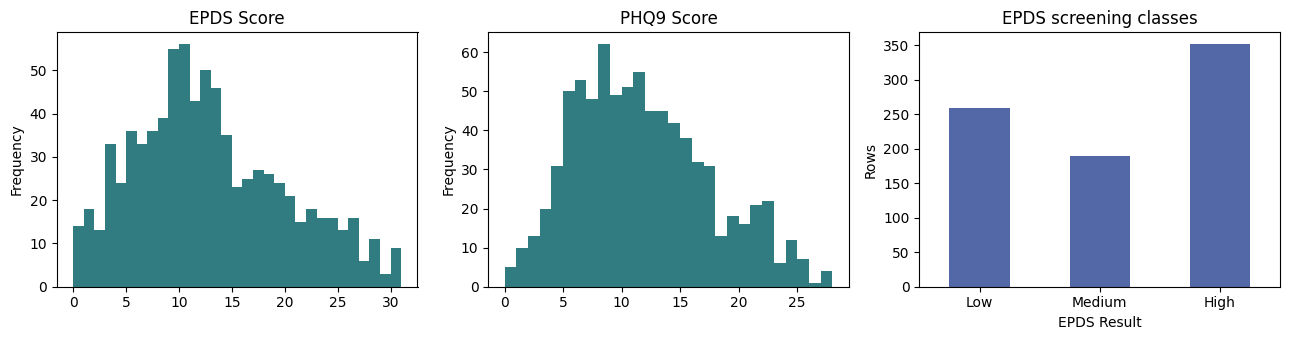

In [3]:
scores = ["EPDS Score", "PHQ9 Score"]
display(data[scores].describe().round(2))
display(data["PHQ9 Result"].value_counts().rename("phq9_result_count").to_frame())
display(data.assign(label=labels).groupby("label")["EPDS Score"]
        .agg(["min", "max", "count"]).reindex(LABELS))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for name, ax in zip(scores, axes[:2]):
    data[name].plot.hist(bins=range(int(data[name].max()) + 2), ax=ax,
                        color="#317C80", title=name)
counts.plot.bar(ax=axes[2], title="EPDS screening classes", color="#5368A7", rot=0)
axes[2].set_ylabel("Rows")
fig.tight_layout()
fig.savefig(GRAPHS / "dataset_distributions.png", dpi=140)
plt.show()

The supplied labels overlap in EPDS score near class boundaries. Use the recorded labels after normalizing capitalization. Keep both scores and both questionnaire results out of the predictor matrix. `None` is a valid survey answer. Handle the invalid disease response as missing.